In [1]:
%%time
# 1) see the newest versions on PyPI
!pip index versions ultralytics 2>/dev/null | head -n 2

# 2) install a pinned version (change the number if the newest above is higher)
ULTRA = '8.4.191'
!pip install ultralytics=={ULTRA} -qq

import ultralytics, torch
from ultralytics import YOLO
print('ultralytics:', ultralytics.__version__, '| torch:', torch.__version__,
      '| GPUs:', torch.cuda.device_count())
assert ultralytics.__version__ == ULTRA

# 3) confirm YOLO26 weights download and load
m = YOLO('yolo26s.pt')
print('model loaded:', m.task, '| classes:', len(m.names))

ultralytics (8.4.192)
Available versions: 8.4.192, 8.4.191, 8.4.190, 8.4.189, 8.4.188, 8.4.187, 8.4.186, 8.4.185, 8.4.184, 8.4.183, 8.4.182, 8.4.181, 8.4.180, 8.4.179, 8.4.178, 8.4.177, 8.4.176, 8.4.175, 8.4.174, 8.4.173, 8.4.172, 8.4.171, 8.4.170, 8.4.169, 8.4.168, 8.4.167, 8.4.166, 8.4.165, 8.4.164, 8.4.163, 8.4.162, 8.4.161, 8.4.160, 8.4.159, 8.4.158, 8.4.157, 8.4.156, 8.4.155, 8.4.154, 8.4.153, 8.4.152, 8.4.151, 8.4.150, 8.4.149, 8.4.148, 8.4.147, 8.4.146, 8.4.145, 8.4.144, 8.4.143, 8.4.142, 8.4.141, 8.4.140, 8.4.139, 8.4.138, 8.4.137, 8.4.136, 8.4.135, 8.4.134, 8.4.133, 8.4.132, 8.4.131, 8.4.130, 8.4.129, 8.4.128, 8.4.127, 8.4.126, 8.4.125, 8.4.124, 8.4.123, 8.4.122, 8.4.121, 8.4.120, 8.4.119, 8.4.118, 8.4.117, 8.4.116, 8.4.115, 8.4.114, 8.4.113, 8.4.112, 8.4.111, 8.4.110, 8.4.109, 8.4.108, 8.4.107, 8.4.106, 8.4.105, 8.4.104, 8.4.103, 8.4.102, 8.4.101, 8.4.100, 8.4.99, 8.4.98, 8.4.97, 8.4.96, 8.4.95, 8.4.94, 8.4.93, 8.4.92, 8.4.91, 8.4.90, 8.4.89, 8.4.88, 8.4.87, 8.4.86, 8.4.85, 8

In [2]:
import os, glob, json, math, random, shutil, warnings
from collections import Counter
import numpy as np, pandas as pd, cv2, torch, yaml
import matplotlib.pyplot as plt
from ultralytics import YOLO
warnings.filterwarnings('ignore')

D = '/kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow'
class CFG:
    SEED = 42
    CSS_ROOT = f'{D}/css-data'
    V8_BASELINE = f'{D}/results_yolov8n_100e/kaggle/working/runs/detect/train/weights/best.pt'
    VIDEO_DIRS = ['/kaggle/input/datasets/hinepo/video-example-for-ppe-red-zone', f'{D}/source_files/source_files']
    WORK = '/kaggle/working'
    CLASSES = ['Hardhat','Mask','NO-Hardhat','NO-Mask','NO-Safety Vest','Person','Safety Cone','Safety Vest','machinery','vehicle']
    # training
    MODEL, EPOCHS, BATCH, IMGSZ, PATIENCE, RUN = 'yolo26s.pt', 80, 16, 640, 25, 'yolo26s_css'
    # tagging
    CONF, PERSON_CONF, VIOL_CONF = 0.35, 0.40, 0.50   # detector floor / person min / min conf to call a violation
    MIN_PERSON_H, EDGE = 0.12, 0.01                   # ignore persons shorter than 12% of frame; "touching edge" margin
    VOTE_K, VOTE_STEP = 1, 2                          # probe frame +-1 neighbour at 2-frame spacing (3 votes)
    SMOOTH_S, MIN_DUR_S, MERGE_GAP_S = 1.0, 0.5, 0.5  # persistence, minimum event length, gap merging
    STRIDE_S = 1.0
    GT_CSV = None                                     # optional: csv with video,item,state,start_s,end_s

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all(CFG.SEED)

In [3]:
VIDEOS = sorted(sum([glob.glob(f'{d}/*.mp4') for d in CFG.VIDEO_DIRS], []))
for v in VIDEOS: print(v)
print('v8 baseline exists:', os.path.exists(CFG.V8_BASELINE))
VIDEO = VIDEOS[0]

/kaggle/input/datasets/hinepo/video-example-for-ppe-red-zone/example_video.mp4
/kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/source_files/source_files/JapanPPE.mp4
/kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/source_files/source_files/hardhat.mp4
/kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/source_files/source_files/indianworkers.mp4
v8 baseline exists: True


In [4]:
def base_id(f): return os.path.basename(f).split('.rf.')[0]

files = {s: sorted(os.listdir(f'{CFG.CSS_ROOT}/{s}/images')) for s in ['train','valid','test']}
ids = {s: {base_id(f) for f in fs} for s, fs in files.items()}
for s in files: print(f'{s}: {len(files[s])} images, {len(ids[s])} unique source ids')
ov = {'train&valid': len(ids['train'] & ids['valid']),
      'train&test':  len(ids['train'] & ids['test']),
      'valid&test':  len(ids['valid'] & ids['test'])}
print('overlapping source ids:', ov)

train: 2605 images, 514 unique source ids
valid: 114 images, 113 unique source ids
test: 82 images, 81 unique source ids
overlapping source ids: {'train&valid': 6, 'train&test': 2, 'valid&test': 0}


In [5]:
leak = any(v > 0 for v in ov.values())
DATA_ROOT = CFG.CSS_ROOT
if leak:
    DATA_ROOT = f'{CFG.WORK}/css_clean'
    keep = {'train': [f for f in files['train'] if base_id(f) not in (ids['valid'] | ids['test'])],
            'valid': [f for f in files['valid'] if base_id(f) not in ids['test']],
            'test':  files['test']}
    for s, fs in keep.items():
        os.makedirs(f'{DATA_ROOT}/{s}/images', exist_ok=True); os.makedirs(f'{DATA_ROOT}/{s}/labels', exist_ok=True)
        for f in fs:
            shutil.copy(f'{CFG.CSS_ROOT}/{s}/images/{f}', f'{DATA_ROOT}/{s}/images/{f}')
            lab = os.path.splitext(f)[0] + '.txt'
            shutil.copy(f'{CFG.CSS_ROOT}/{s}/labels/{lab}', f'{DATA_ROOT}/{s}/labels/{lab}')
        print(s, 'kept', len(fs), 'of', len(files[s]))
print('DATA_ROOT:', DATA_ROOT, '| leakage found:', leak)

YAML = f'{CFG.WORK}/data.yaml'
yaml.dump({'train': f'{DATA_ROOT}/train/images', 'val': f'{DATA_ROOT}/valid/images',
           'test': f'{DATA_ROOT}/test/images', 'nc': len(CFG.CLASSES), 'names': CFG.CLASSES}, open(YAML, 'w'))

rows = []
for s in ['train','valid','test']:
    c = Counter()
    for f in glob.glob(f'{DATA_ROOT}/{s}/labels/*.txt'):
        for line in open(f):
            if line.strip(): c[CFG.CLASSES[int(line.split()[0])]] += 1
    rows.append({'split': s, **c})
pd.DataFrame(rows).set_index('split').fillna(0).astype(int)

train kept 2565 of 2605
valid kept 114 of 114
test kept 82 of 82
DATA_ROOT: /kaggle/working/css_clean | leakage found: True


,Safety Cone,vehicle,Safety Vest,Person,Hardhat,NO-Safety Vest,NO-Mask,Mask,NO-Hardhat,machinery
split,,,,,,,,,,
train,3346,1521,2986,9397,3087,3904,3056,1613,2280,5163
valid,44,42,41,166,79,106,74,21,69,55
test,92,41,61,174,110,90,79,28,41,44


In [6]:
model = YOLO(CFG.MODEL)
model.train(data=YAML, imgsz=CFG.IMGSZ, epochs=CFG.EPOCHS, batch=CFG.BATCH, patience=CFG.PATIENCE,
            seed=CFG.SEED, project=f'{CFG.WORK}/runs', name=CFG.RUN, exist_ok=True,
            device=[0, 1], amp=True, plots=True, workers=4)   # if DDP errors in the notebook, use device=0
BEST = glob.glob(f'{CFG.WORK}/**/{CFG.RUN}/weights/best.pt', recursive=True)[0]
print('best weights:', BEST)

New https://pypi.org/project/ultralytics/8.4.192 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       2/80      3.16G       1.46      2.092    0.01113         50        640: 100% ━━━━━━━━━━━━ 161/161 5.4it/s 29.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 6.2it/s 0.6s
                   all        114        697      0.692       0.55      0.596      0.269

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/80      3.16G      1.479       1.88    0.01123         35        640: 100% ━━━━━━━━━━━━ 161/161 5.4it/s 29.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 6.1it/s 0.7s
                   all        114        697      0.775      0.555      0.621      0.317

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/80      3.16G      1.451      1.781    0.01112         54        640: 100% ━━━━━━━━━━━━ 

In [7]:
SPLIT_KEY = {'valid': 'val', 'test': 'test'}   # our label -> key in data.yaml

def eval_split(weights, split):
    r = YOLO(weights).val(data=YAML, split=SPLIT_KEY[split], imgsz=CFG.IMGSZ, batch=CFG.BATCH,
                          device=0, plots=False, verbose=False)
    per = pd.DataFrame({'class': [r.names[i] for i in r.box.ap_class_index],
                        'AP50': r.box.ap50, 'AP50-95': r.box.ap})
    return dict(P=r.box.mp, R=r.box.mr, mAP50=r.box.map50, mAP50_95=r.box.map), per

models = {'yolo26s (ours)': BEST}
if os.path.exists(CFG.V8_BASELINE): models['yolov8n (old)'] = CFG.V8_BASELINE

summ, perc = [], []
for name, w in models.items():
    for split in ['valid', 'test']:
        m, per = eval_split(w, split)
        summ.append({'model': name, 'split': split, **m})
        perc.append(per.assign(model=name, split=split))
summary = pd.DataFrame(summ).round(3); summary.to_csv(f'{CFG.WORK}/detector_summary.csv', index=False)
per_class = pd.concat(perc); per_class.to_csv(f'{CFG.WORK}/detector_per_class.csv', index=False)
display(summary)
display(per_class[per_class.split == 'test'].pivot(index='class', columns='model', values='AP50-95').round(3))

Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1536.6±444.2 MB/s, size: 47.1 KB)
val: Scanning /kaggle/working/css_clean/valid/labels.cache... 114 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 114/114 29.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.4it/s 1.8s
                   all        114        697      0.907       0.81      0.859       0.58
Speed: 0.9ms preprocess, 10.7ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.191 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1192.7±410.0 MB/s, size: 38.3 KB)
val: Scanning /kaggle/working/css_clean/test/labels... 82

,model,split,P,R,mAP50,mAP50_95
0,yolo26s (ours),valid,0.907,0.810,0.859,0.580
1,yolo26s (ours),test,0.926,0.757,0.811,0.530
2,yolov8n (old),valid,0.916,0.727,0.802,0.499
3,yolov8n (old),test,0.858,0.695,0.749,0.452


model,yolo26s (ours),yolov8n (old)
class,,
Hardhat,0.654,0.588
Mask,0.545,0.515
NO-Hardhat,0.357,0.280
NO-Mask,0.394,0.358
NO-Safety Vest,0.538,0.454
Person,0.642,0.522
Safety Cone,0.254,0.193
Safety Vest,0.649,0.574
machinery,0.713,0.625


In [8]:
class Video:
    def __init__(self, path):
        self.path, self.cap = path, cv2.VideoCapture(path)
        assert self.cap.isOpened(), path
        self.fps = float(self.cap.get(cv2.CAP_PROP_FPS))
        self.n = int(self.cap.get(cv2.CAP_PROP_FRAME_COUNT))
        self.w, self.h = int(self.cap.get(3)), int(self.cap.get(4))
        self.duration = self.n / self.fps
        self.name = os.path.splitext(os.path.basename(path))[0]
    def t(self, i): return i / self.fps
    def idx(self, t): return int(round(t * self.fps))
    def frame(self, i):
        i = min(max(i, 0), self.n - 1)
        for k in range(5):                       # last frames sometimes fail to decode; step back
            self.cap.set(cv2.CAP_PROP_POS_FRAMES, max(i - k, 0))
            ok, img = self.cap.read()
            if ok: return img
        raise RuntimeError(f'cannot read frame {i}')

V = Video(VIDEO)
print(f'{V.name}: {V.w}x{V.h}, fps={V.fps:.3f}, frames={V.n}, duration={V.duration:.2f}s')

# seek vs sequential decode: values near 0 mean seeking is frame-accurate
cap = cv2.VideoCapture(VIDEO); seq = [cap.read()[1] for _ in range(61)]
print([round(float(np.abs(seq[i].astype(int) - V.frame(i).astype(int)).mean()), 3) for i in (0, 30, 60)])

example_video: 1280x720, fps=29.000, frames=697, duration=24.03s
[0.0, 0.0, 0.0]


In [9]:
ITEMS = {'hardhat': ('Hardhat', 'NO-Hardhat'), 'vest': ('Safety Vest', 'NO-Safety Vest')}
BAND = {'hardhat': (0.0, 0.35), 'vest': (0.20, 0.75)}   # vertical band of the person box where evidence must fall

def person_records(dets, W, H):
    recs = []
    for p in dets:
        if p['cls'] == 'Person' and p['conf'] >= CFG.PERSON_CONF:
            x1, y1, x2, y2 = p['box']
            recs.append(dict(box=p['box'], conf=p['conf'], tiny=(y2 - y1) < CFG.MIN_PERSON_H * H,
                             head_cropped=y1 <= CFG.EDGE * H, ev={k: [] for k in ITEMS}))
    for d in dets:                                       # assign each PPE box to the tightest person box containing it
        for item, (pos, neg) in ITEMS.items():
            if d['cls'] not in (pos, neg): continue
            cx, cy = (d['box'][0] + d['box'][2]) / 2, (d['box'][1] + d['box'][3]) / 2
            best = None
            for r in recs:
                x1, y1, x2, y2 = r['box']; h = y2 - y1; lo, hi = BAND[item]
                if x1 <= cx <= x2 and y1 + lo * h <= cy <= y1 + hi * h:
                    area = (x2 - x1) * h
                    if best is None or area < best[0]: best = (area, r)
            if best: best[1]['ev'][item].append(d)
    for r in recs:
        r['state'] = {}
        for item, (pos, neg) in ITEMS.items():
            c = r['ev'][item]
            if c:
                b = max(c, key=lambda d: d['conf'])
                s = 'compliant' if b['cls'] == pos else 'violation'
                # a visible hardhat proves compliance; "no hardhat" on a cropped head proves nothing
                if item == 'hardhat' and s == 'violation' and r['head_cropped']: s = 'uncertain'
                r['state'][item] = (s, b['conf'])
            else:
                r['state'][item] = ('uncertain', 0.0)
    return recs

def scene_state(recs, item):
    recs = [r for r in recs if not r['tiny']]
    if not recs: return ('no_person', 0.0)
    sts = [r['state'][item] for r in recs]
    viol = [c for s, c in sts if s == 'violation' and c >= CFG.VIOL_CONF]
    if viol: return ('violation', max(viol))
    if all(s == 'compliant' for s, _ in sts): return ('compliant', min(c for _, c in sts))
    return ('uncertain', 0.0)

class Perceiver:
    def __init__(self, video, model):
        self.v, self.m, self.cache, self.touched = video, model, {}, set()
    def dets(self, i):
        if i not in self.cache:
            r = self.m.predict(self.v.frame(i), conf=CFG.CONF, imgsz=CFG.IMGSZ, device=0, verbose=False)[0]
            b = r.boxes
            self.cache[i] = [dict(cls=r.names[int(c)], conf=float(s), box=[float(x) for x in xy])
                             for xy, s, c in zip(b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy())]
        return self.cache[i]
    def state(self, i):
        self.touched.add(i)
        recs = person_records(self.dets(i), self.v.w, self.v.h)
        return {'n_person': sum(not r['tiny'] for r in recs), 'items': {it: scene_state(recs, it) for it in ITEMS}}

P = Perceiver(V, YOLO(BEST))
print(P.state(0))

{'n_person': 3, 'items': {'hardhat': ('uncertain', 0.0), 'vest': ('violation', 0.8108413815498352)}}


In [10]:
def coarse_scan(P, stride_s):
    step = max(1, round(P.v.fps * stride_s))
    idxs = list(range(0, P.v.n, step))
    if idxs[-1] != P.v.n - 1: idxs.append(P.v.n - 1)
    rows = []
    for i in idxs:
        s = P.state(i)
        row = {'frame': i, 't': P.v.t(i), 'n_person': s['n_person']}
        for it in ITEMS: row[f'{it}_state'], row[f'{it}_conf'] = s['items'][it]
        rows.append(row)
    return pd.DataFrame(rows)

def smooth_runs(x, min_run):                      # flip runs shorter than min_run that sit between equal neighbours
    x, n, i = list(x), len(x), 0
    while i < n:
        j = i
        while j < n and x[j] == x[i]: j += 1
        if (j - i) < min_run and i > 0 and j < n and x[i - 1] == x[j]:
            for k in range(i, j): x[k] = x[i - 1]
        i = j
    return x

def probe(P, i, item):                            # majority vote over neighbouring frames
    idxs = [min(max(i + o * CFG.VOTE_STEP, 0), P.v.n - 1) for o in range(-CFG.VOTE_K, CFG.VOTE_K + 1)]
    votes = [P.state(j)['items'][item][0] == 'violation' for j in idxs]
    return sum(votes) * 2 > len(votes)

def refine(P, a, b, item, pa):                    # first frame in (a, b] where predicate != pa
    lo, hi = a, b
    while hi - lo > 1:
        m = (lo + hi) // 2
        if probe(P, m, item) == pa: lo = m
        else: hi = m
    return hi

def merge_filter(iv, fps):                        # iv: list of (start_frame, end_frame)
    out = []
    for s, e in sorted(iv):
        if out and (s - out[-1][1]) / fps < CFG.MERGE_GAP_S: out[-1][1] = max(out[-1][1], e)
        else: out.append([s, e])
    return [(s, e) for s, e in out if (e - s) / fps >= CFG.MIN_DUR_S]

def coarse_runs(df, item, state, n):              # runs of a state at coarse resolution
    st, fr, out, start = df[f'{item}_state'].tolist(), df.frame.tolist(), [], None
    for k, s in enumerate(st):
        if s == state and start is None: start = fr[k]
        if s != state and start is not None: out.append((start, fr[k])); start = None
    if start is not None: out.append((start, n))
    return out

COLS = ['video','item','state','start_s','end_s','start_frame','end_frame','conf','resolution']
def tag_item(P, item, stride_s, refine_on=True):
    V = P.v
    df = coarse_scan(P, stride_s)
    min_run = max(1, round(CFG.SMOOTH_S / stride_s))
    pred = smooth_runs((df[f'{item}_state'] == 'violation').tolist(), min_run)
    fr, iv, start = df.frame.tolist(), [], (0 if pred[0] else None)
    for k in range(1, len(pred)):
        if pred[k] != pred[k - 1]:
            b = refine(P, fr[k - 1], fr[k], item, pred[k - 1]) if refine_on else fr[k]
            if pred[k]: start = b
            else: iv.append((start, b)); start = None
    if start is not None: iv.append((start, V.n))
    ev = []
    for s, e in merge_filter(iv, V.fps):
        m = df[(df.frame >= s) & (df.frame < e) & (df[f'{item}_state'] == 'violation')]
        ev.append([V.name, item, 'violation', V.t(s), V.t(e), s, e, float(m[f'{item}_conf'].mean()) if len(m) else 0.0,
                   'fine' if refine_on else 'coarse'])
    for s, e in coarse_runs(df, item, 'uncertain', V.n):      # "not visible / unclear" segments, coarse resolution only
        if (e - s) / V.fps >= CFG.MIN_DUR_S:
            ev.append([V.name, item, 'uncertain', V.t(s), V.t(e), s, e, 0.0, 'coarse'])
    return pd.DataFrame(ev, columns=COLS), df

def run_pipeline(P, stride_s, refine_on=True):
    P.touched = set()
    evs = [tag_item(P, it, stride_s, refine_on)[0] for it in ITEMS]
    return pd.concat(evs, ignore_index=True), len(P.touched)

In [11]:
def mask(ev, item, state='violation'):
    m = np.zeros(V.n, bool)
    for r in ev[(ev.item == item) & (ev.state == state)].itertuples(): m[r.start_frame:r.end_frame] = True
    return m

def boundary_err(ref, pred):
    errs = []
    for item in ITEMS:
        r = ref[(ref.item == item) & (ref.state == 'violation')]; p = pred[(pred.item == item) & (pred.state == 'violation')]
        if len(p) == 0: continue
        for x in r.itertuples():
            errs += [abs(p.start_s - x.start_s).min(), abs(p.end_s - x.end_s).min()]
    return float(np.mean(errs)) if errs else np.nan

CONFIGS = [('dense (every frame)', 1 / V.fps, False), ('coarse 2.0s + refine', 2.0, True),
           ('coarse 1.0s (no refine)', 1.0, False), ('coarse 1.0s + refine', 1.0, True), ('coarse 0.5s + refine', 0.5, True)]
RESULTS, rows = {}, []
for name, stride, ref_on in CONFIGS:
    ev, nfr = run_pipeline(P, stride, ref_on)
    RESULTS[name] = ev
    rows.append({'config': name, 'frames_processed': nfr, 'pct_of_video': round(100 * nfr / V.n, 1), 'events': int(((ev.state == 'violation')).sum())})
dense = RESULTS['dense (every frame)']
for r, (name, _, _) in zip(rows, CONFIGS):
    ev = RESULTS[name]
    r['tIoU_vs_dense'] = round(np.mean([(mask(ev, it) & mask(dense, it)).sum() / max((mask(ev, it) | mask(dense, it)).sum(), 1) for it in ITEMS]), 3)
    r['boundary_err_s'] = round(boundary_err(dense, ev), 3)
comparison = pd.DataFrame(rows); comparison.to_csv(f'{CFG.WORK}/tagging_comparison.csv', index=False); comparison

,config,frames_processed,pct_of_video,events,tIoU_vs_dense,boundary_err_s
0,dense (every frame),697,100.0,5,1.000,0.000
1,coarse 2.0s + refine,118,16.9,5,0.846,0.562
2,coarse 1.0s (no refine),25,3.6,5,0.512,2.341
3,coarse 1.0s + refine,117,16.8,6,0.918,0.007
4,coarse 0.5s + refine,133,19.1,7,0.792,0.107


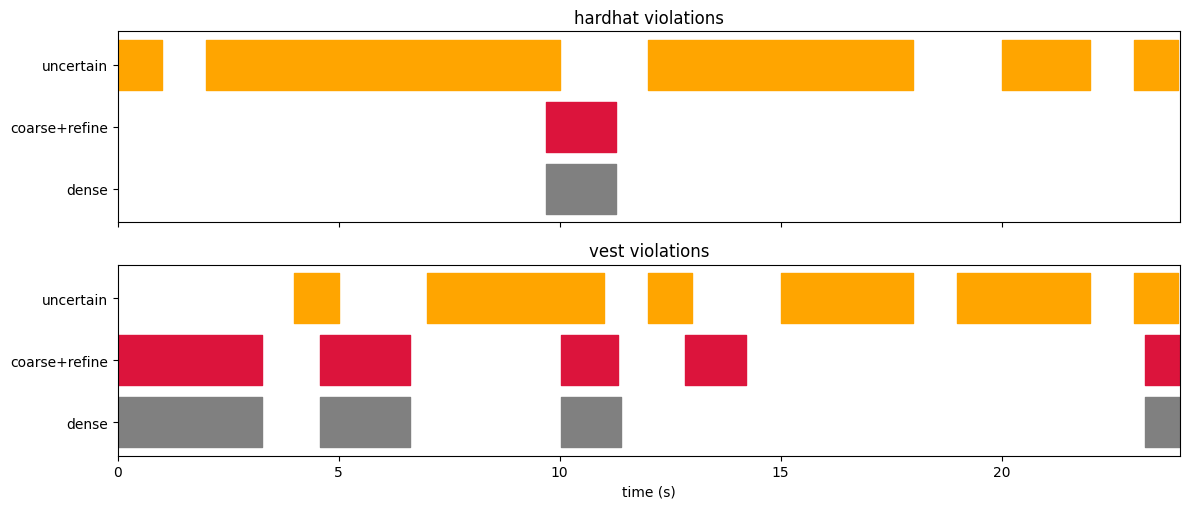

In [12]:
fig, axes = plt.subplots(len(ITEMS), 1, figsize=(12, 2.6 * len(ITEMS)), sharex=True)
for ax, item in zip(np.atleast_1d(axes), ITEMS):
    for y, name in enumerate(['dense (every frame)', 'coarse 1.0s + refine']):
        ev = RESULTS[name]; ev = ev[(ev.item == item) & (ev.state == 'violation')]
        ax.broken_barh([(r.start_s, r.end_s - r.start_s) for r in ev.itertuples()], (y, 0.8), color=['gray', 'crimson'][y])
    unc = RESULTS['coarse 1.0s + refine']; unc = unc[(unc.item == item) & (unc.state == 'uncertain')]
    ax.broken_barh([(r.start_s, r.end_s - r.start_s) for r in unc.itertuples()], (2, 0.8), color='orange')
    ax.set_yticks([0.4, 1.4, 2.4]); ax.set_yticklabels(['dense', 'coarse+refine', 'uncertain']); ax.set_title(f'{item} violations')
plt.xlabel('time (s)'); plt.xlim(0, V.duration); plt.tight_layout(); plt.show()

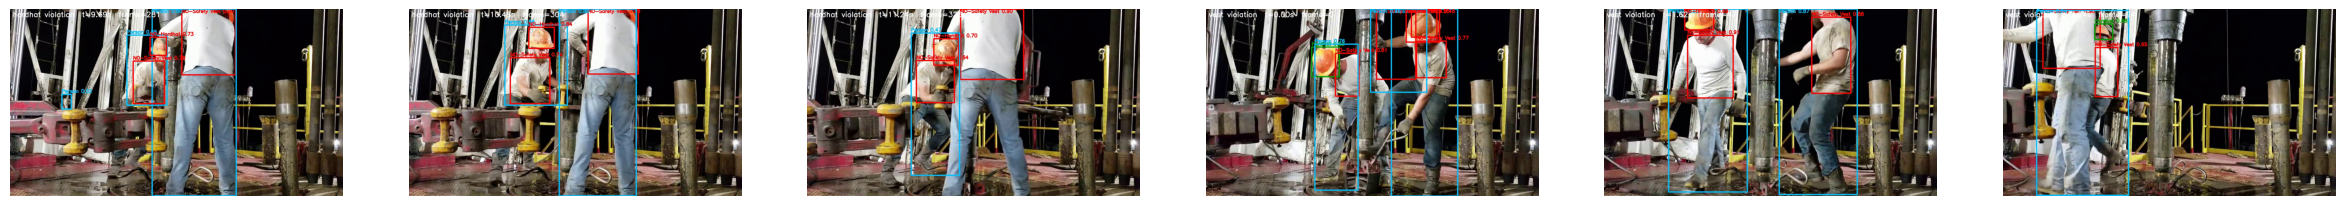

In [13]:
COL = {'Person': (255, 191, 0), 'Hardhat': (0, 160, 0), 'Safety Vest': (0, 255, 0), 'NO-Hardhat': (0, 0, 255), 'NO-Safety Vest': (0, 0, 255)}
def render(P, i, label):
    img = P.v.frame(i).copy()
    for d in P.dets(i):
        if d['cls'] in COL:
            x1, y1, x2, y2 = map(int, d['box'])
            cv2.rectangle(img, (x1, y1), (x2, y2), COL[d['cls']], 3)
            cv2.putText(img, f"{d['cls']} {d['conf']:.2f}", (x1, max(y1 - 6, 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, COL[d['cls']], 2)
    cv2.putText(img, f'{label}  t={P.v.t(i):.2f}s  frame={i}', (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
    return img

CHOSEN = 'coarse 1.0s + refine'
events = RESULTS[CHOSEN].copy()
os.makedirs(f'{CFG.WORK}/evidence', exist_ok=True)
ev_paths = {}
for k, r in enumerate(events[events.state == 'violation'].itertuples()):
    paths = []
    for tag, i in [('start', r.start_frame), ('mid', (r.start_frame + r.end_frame) // 2), ('end', r.end_frame - 1)]:
        p = f'{CFG.WORK}/evidence/{V.name}_{r.item}_{k}_{tag}.jpg'
        cv2.imwrite(p, render(P, i, f'{r.item} violation')); paths.append(p)
    ev_paths[(r.item, r.start_frame)] = paths
events['evidence'] = [ev_paths.get((r.item, r.start_frame), []) for r in events.itertuples()]

first = [p for ps in list(ev_paths.values())[:2] for p in ps]
if first:
    fig, axs = plt.subplots(1, len(first), figsize=(5 * len(first), 4))
    for ax, p in zip(np.atleast_1d(axs), first): ax.imshow(cv2.imread(p)[..., ::-1]); ax.axis('off')
    plt.show()


In [14]:
def eval_vs_gt(pred, gt, thr=0.5):
    out = []
    for item in ITEMS:
        g = gt[(gt.video == V.name) & (gt.item == item) & (gt.state == 'violation')]
        p = pred[(pred.item == item) & (pred.state == 'violation')]
        gm, pm = np.zeros(V.n, bool), mask(pred, item)
        for r in g.itertuples(): gm[V.idx(r.start_s):V.idx(r.end_s)] = True
        def iou(a, b):
            inter = max(0, min(a.end_s, b.end_s) - max(a.start_s, b.start_s))
            return inter / max((a.end_s - a.start_s) + (b.end_s - b.start_s) - inter, 1e-9)
        tp_p = sum(any(iou(a, b) >= thr for b in g.itertuples()) for a in p.itertuples())
        tp_g = sum(any(iou(a, b) >= thr for a in p.itertuples()) for b in g.itertuples())
        prec, rec = tp_p / max(len(p), 1), tp_g / max(len(g), 1)
        out.append({'item': item, 'frame_tIoU': (gm & pm).sum() / max((gm | pm).sum(), 1),
                    'precision@0.5': prec, 'recall@0.5': rec, 'F1@0.5': 2 * prec * rec / max(prec + rec, 1e-9)})
    return pd.DataFrame(out).round(3)

if CFG.GT_CSV and os.path.exists(CFG.GT_CSV):
    gt = pd.read_csv(CFG.GT_CSV)
    display(pd.concat({n: eval_vs_gt(RESULTS[n], gt) for n in RESULTS}))
else:
    print('No annotation file set: skipping (the dense run is a reference, not ground truth).')

No annotation file set: skipping (the dense run is a reference, not ground truth).


In [15]:
index = {'video': V.name, 'path': V.path, 'fps': V.fps, 'duration_s': V.duration, 'n_frames': V.n,
         'config': {k: v for k, v in vars(CFG).items() if k.isupper() and k in
                    ['CONF', 'PERSON_CONF', 'VIOL_CONF', 'VOTE_K', 'VOTE_STEP', 'SMOOTH_S', 'MIN_DUR_S', 'MERGE_GAP_S', 'STRIDE_S']},
         'detector': BEST, 'frames_processed': int(comparison.set_index('config').loc[CHOSEN, 'frames_processed']),
         'events': json.loads(events.to_json(orient='records'))}
json.dump(index, open(f'{CFG.WORK}/event_index.json', 'w'), indent=2)
events.drop(columns='evidence').to_csv(f'{CFG.WORK}/events.csv', index=False)
print('saved:', os.listdir(CFG.WORK))

saved: ['yolo26s.pt', 'css_clean', 'tagging_comparison.csv', 'events.csv', 'runs', 'data.yaml', 'detector_summary.csv', 'detector_per_class.csv', '__notebook__.ipynb', 'weights', 'event_index.json', 'evidence']
